# 3. Phase plane

Nullclines, equilibria with eigenvalues, and trajectories for the Morris-Lecar model.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pyxpp
m = pyxpp.load("../lecar.ode")

## Nullclines in a chosen window (Viewaxes > 2D, then Nullcline > New)

In [2]:
nc = m.nullclines(x="v", y="w", xlo=-0.6, xhi=0.5, ylo=-0.1, yhi=0.6)
{k: v.shape for k, v in nc.items()}

{'V': (290, 2), 'W': (180, 2)}

## Equilibria

At `iapp=0` there are three equilibria. Newton's method from three guesses:

In [3]:
eqs = [m.equilibrium({"v": v0, "w": w0}) for v0, w0 in [(-0.5, 0), (-0.08, 0.08), (0.0, 0.2)]]
for e in eqs:
    print(e, np.round(e.eigenvalues, 4))

<Equilibrium stable V=-0.495617, W=0.000270383> [-0.4737+0.j -1.3173+0.j]
<Equilibrium unstable V=-0.0790208, W=0.078042> [ 1.7633+0.j -0.1712+0.j]
<Equilibrium unstable V=0.00137318, W=0.20418> [1.1013+0.j 0.4098+0.j]


## Putting it together

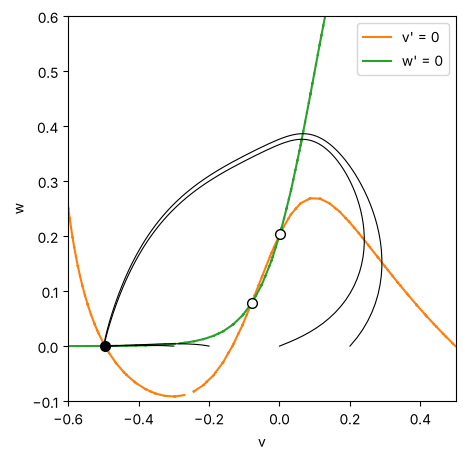

In [4]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(*nc["V"].T, color="C1", label="v' = 0")
ax.plot(*nc["W"].T, color="C2", label="w' = 0")
for v0 in [-0.3, -0.2, 0.0, 0.2]:
    tr = m.run(v=v0, w=0.0, total=100)
    ax.plot(tr["v"], tr["w"], "k", lw=0.8)
for e in eqs:
    ax.plot(e.x["V"], e.x["W"], "o", color="k", mfc="k" if e.stable else "w", ms=7)
ax.set(xlim=(-0.6, 0.5), ylim=(-0.1, 0.6), xlabel="v", ylabel="w"); ax.legend();

## With applied current the middle branch loses its equilibria and a limit cycle appears

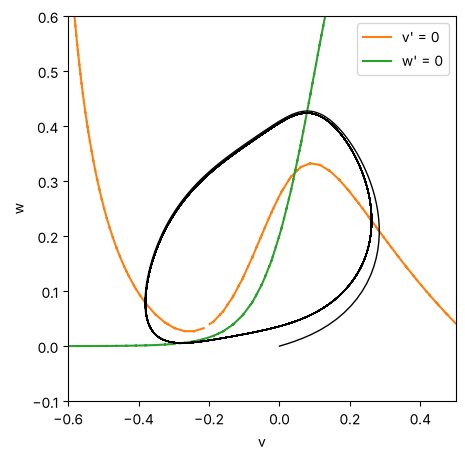

In [5]:
m.pars["iapp"] = 0.1
nc = m.nullclines()
tr = m.run(v=0, w=0, total=200)
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(*nc["V"].T, color="C1", label="v' = 0")
ax.plot(*nc["W"].T, color="C2", label="w' = 0")
ax.plot(tr["v"], tr["w"], "k", lw=1)
ax.set(xlim=(-0.6, 0.5), ylim=(-0.1, 0.6), xlabel="v", ylabel="w"); ax.legend();